# ML Pipeline Automation: walkthrough

How the automated pipeline keeps a credit-risk model healthy: the data, every pipeline stage, and what happens when the world changes.

**Contents**
1. Setup
2. One day's batch: structure and profiling
3. Exploratory analysis of the applicant data
4. What changes over time (data drift and concept drift)
5. Validation: catching bad batches
6. Training and evaluation metrics
7. Model registry and versioning
8. Monitoring: PSI and live performance
9. Replaying 60 days of the pipeline
10. Did automation matter? Frozen model vs pipeline
11. Ethics and limitations

## 1. Setup

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pipeline.ingest import simulate_batch, DATA_DRIFT_DAY, CONCEPT_DRIFT_DAY
from pipeline.validate import validate
from pipeline.train import train_candidate, FEATURES, metrics
from pipeline.monitor import psi, drift_report
from pipeline.config import NUMERIC, CATEGORICAL, TARGET
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. One day's batch

In [2]:
day5 = simulate_batch(5)
print(day5.shape); day5.head(8)

(800, 15)

,application_id,application_date,age,income_k,loan_amount_k,term_months,credit_score,employment_years,debt_to_income,num_credit_lines,recent_inquiries,channel,purpose,home_ownership,defaulted
0,A005-0000,2026-01-10,24.000,32.500,5.600,48,702.000,1.700,0.278,5,2,branch,other,rent,0
1,A005-0001,2026-01-10,49.000,62.800,21.100,36,811.000,9.500,0.361,4,2,branch,home_improvement,mortgage,0
2,A005-0002,2026-01-10,47.000,24.300,13.800,24,761.000,4.300,0.451,2,0,online,debt_consolidation,rent,0
3,A005-0003,2026-01-10,41.000,19.700,15.900,36,816.000,4.200,0.355,6,2,online,home_improvement,mortgage,0
4,A005-0004,2026-01-10,32.000,64.000,17.100,36,714.000,4.300,0.223,3,1,online,car,own,0
5,A005-0005,2026-01-10,31.000,43.400,5.500,36,804.000,11.400,0.220,7,0,online,car,rent,0
6,A005-0006,2026-01-10,42.000,48.300,13.300,48,725.000,2.500,0.694,7,0,online,home_improvement,mortgage,0
7,A005-0007,2026-01-10,32.000,49.100,20.400,24,601.000,2.900,0.235,5,0,online,debt_consolidation,mortgage,0


In [3]:
day5.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   application_id    800 non-null    str    
 1   application_date  800 non-null    str    
 2   age               800 non-null    float64
 3   income_k          800 non-null    float64
 4   loan_amount_k     800 non-null    float64
 5   term_months       800 non-null    int64  
 6   credit_score      800 non-null    float64
 7   employment_years  800 non-null    float64
 8   debt_to_income    800 non-null    float64
 9   num_credit_lines  800 non-null    int64  
 10  recent_inquiries  800 non-null    int64  
 11  channel           800 non-null    str    
 12  purpose           800 non-null    str    
 13  home_ownership    800 non-null    str    
 14  defaulted         800 non-null    int64  
dtypes: float64(6), int64(4), str(5)
memory usage: 93.9 KB

In [4]:
day5[NUMERIC].describe().T

,count,mean,std,min,25%,50%,75%,max
age,800.000,41.212,12.046,18.000,32.750,41.500,49.000,76.000
income_k,800.000,40.191,16.010,11.800,29.375,37.750,49.100,124.700
loan_amount_k,800.000,12.451,8.110,1.500,6.875,10.500,15.525,51.800
term_months,800.000,34.335,15.139,12.000,24.000,36.000,48.000,60.000
credit_score,800.000,718.928,72.137,496.000,669.000,716.500,768.000,950.000
employment_years,800.000,5.976,4.194,0.200,2.800,4.900,8.300,26.700
debt_to_income,800.000,0.331,0.123,0.010,0.248,0.330,0.414,0.730
num_credit_lines,800.000,5.005,2.183,0.000,3.000,5.000,6.000,12.000
recent_inquiries,800.000,0.897,0.989,0.000,0.000,1.000,1.000,7.000


In [5]:
day5[CATEGORICAL].describe().T

,count,unique,top,freq
channel,800,3,online,513
purpose,800,5,car,250
home_ownership,800,3,mortgage,345


## 3. Exploratory analysis
Two weeks of pre-drift data.

11,200 applications, default rate 11.4%

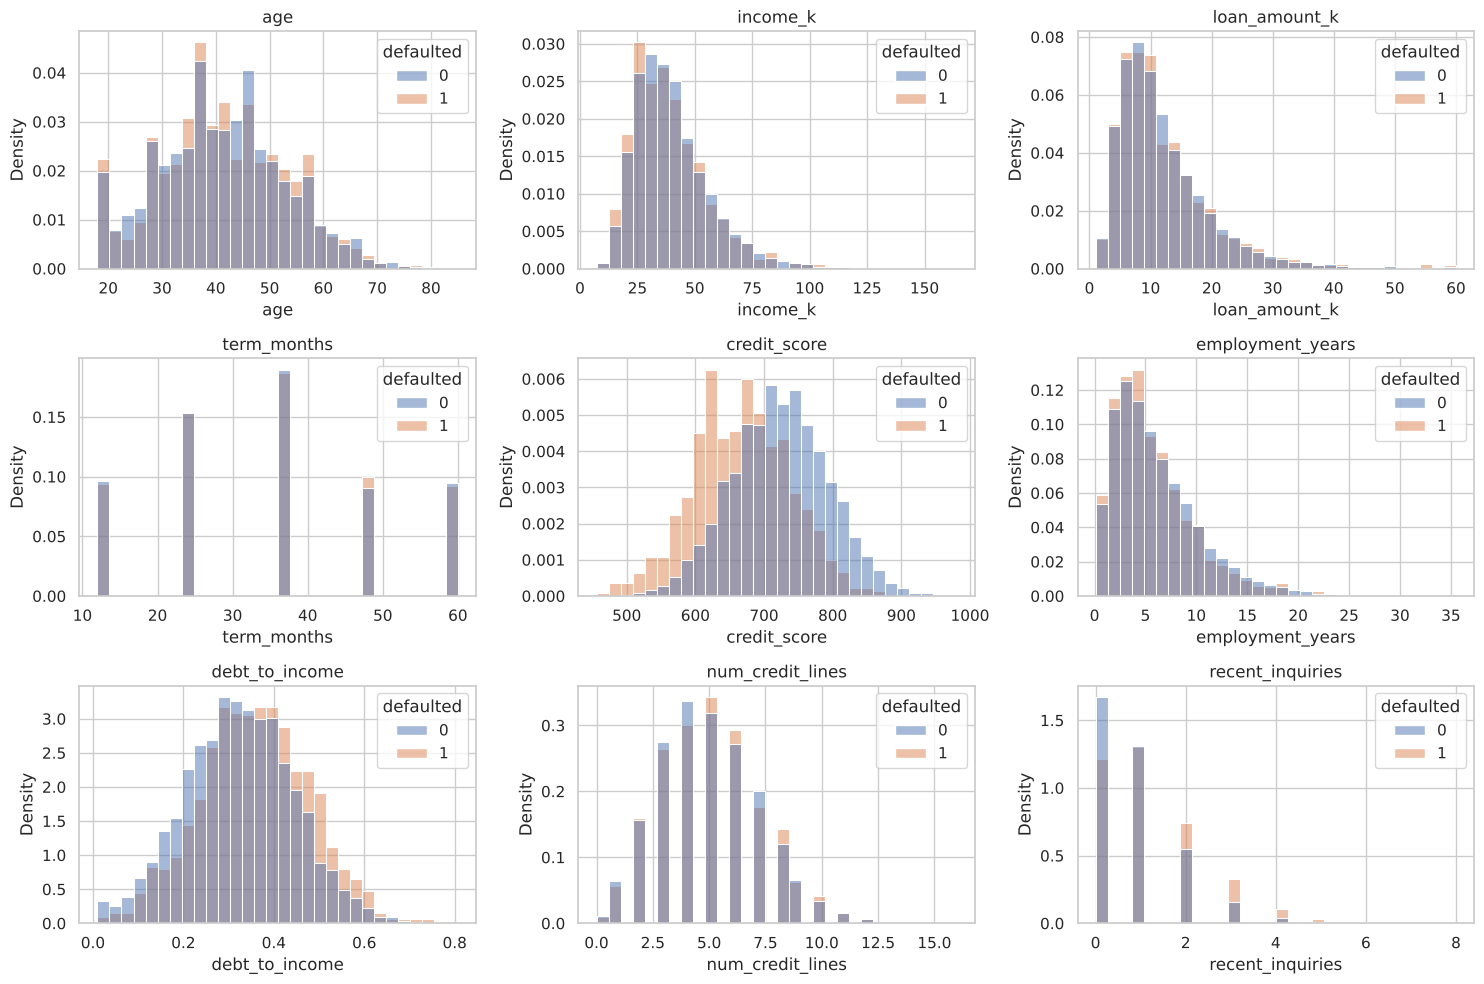

In [6]:
base = pd.concat([simulate_batch(d) for d in range(14)], ignore_index=True)
print(f"{len(base):,} applications, default rate {base[TARGET].mean():.1%}")
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), NUMERIC):
    sns.histplot(base, x=c, hue=TARGET, bins=30, ax=ax, stat="density", common_norm=False); ax.set_title(c)
plt.tight_layout()

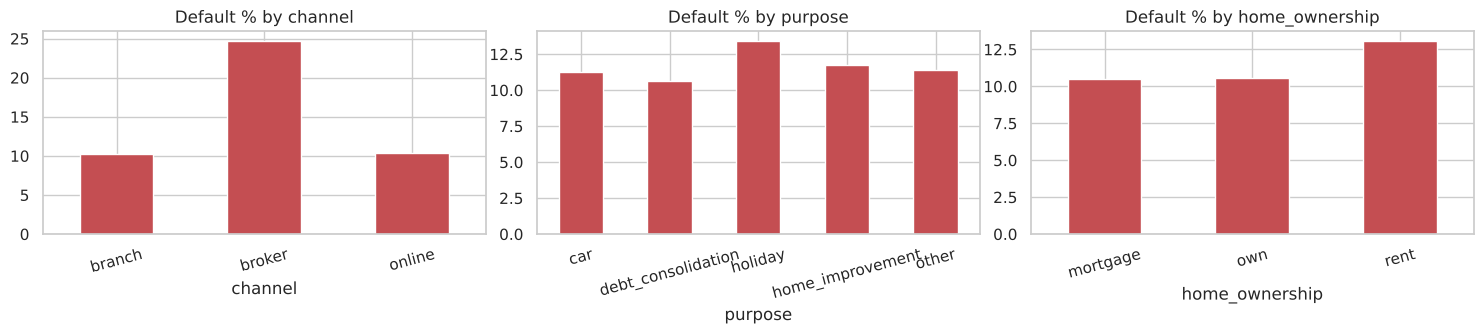

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, CATEGORICAL):
    base.groupby(c)[TARGET].mean().mul(100).plot.bar(ax=ax, rot=15, color="#c44e52"); ax.set_title(f"Default % by {c}")
plt.tight_layout()

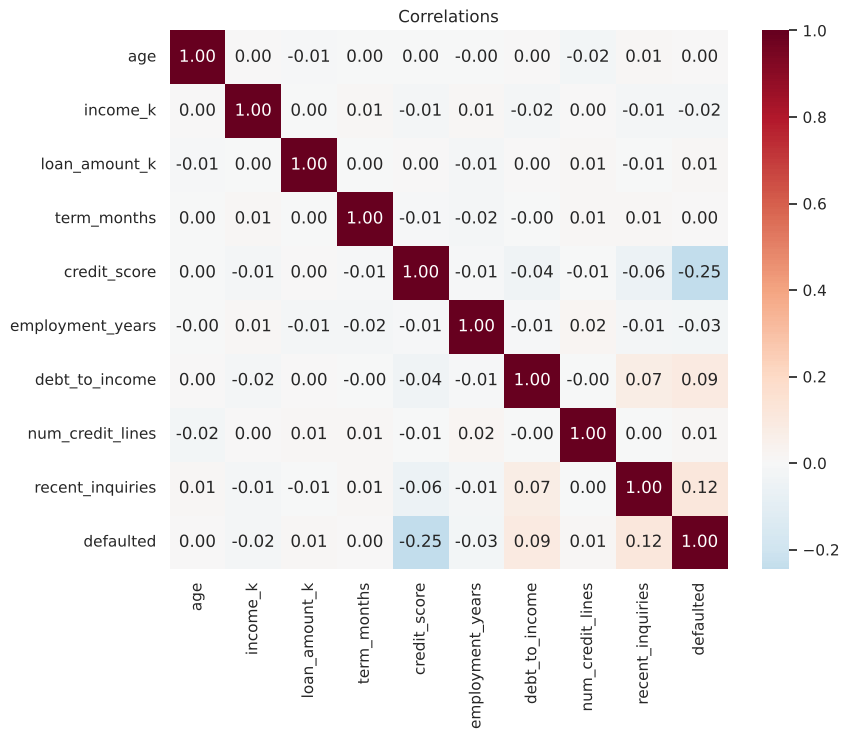

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(base[NUMERIC + [TARGET]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("Correlations");

## 4. What changes over time

In [9]:
early = pd.concat([simulate_batch(d) for d in range(10, 20)])
mid = pd.concat([simulate_batch(d) for d in range(28, 38)])
late = pd.concat([simulate_batch(d) for d in range(45, 55)])
pd.DataFrame({name: {"broker share": (d.channel == "broker").mean(), "median income £k": d.income_k.median(),
                     "median credit score": d.credit_score.median(), "default rate": d[TARGET].mean()}
              for name, d in [("days 10–19", early), ("days 28–37 (data drift)", mid), ("days 45–54 (concept drift)", late)]})

,days 10–19,days 28–37 (data drift),days 45–54 (concept drift)
broker share,0.080,0.300,0.295
median income £k,36.600,33.900,33.900
median credit score,716.000,701.500,702.000
default rate,0.115,0.150,0.207


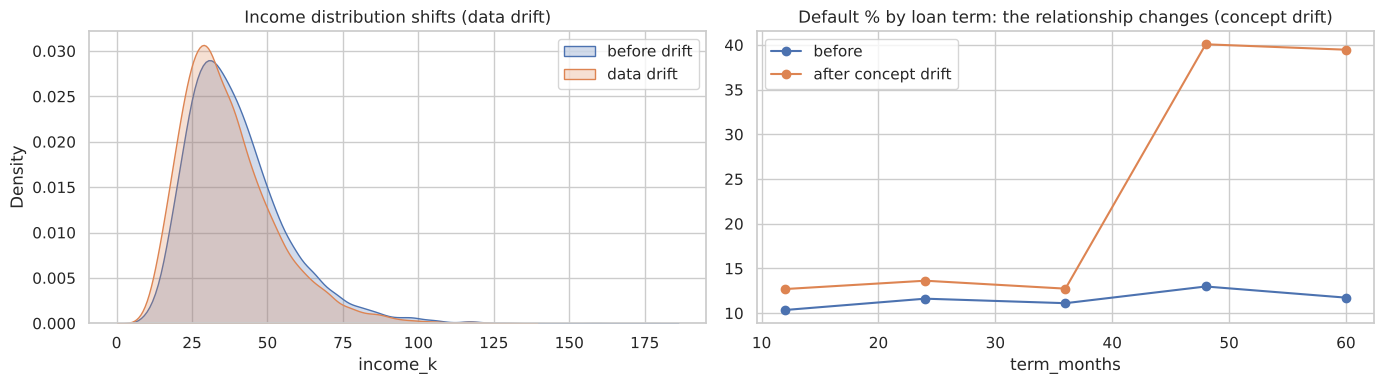

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, d in [("before drift", early), ("data drift", mid)]:
    sns.kdeplot(d.income_k, ax=axes[0], label=name, fill=True)
axes[0].set_title("Income distribution shifts (data drift)"); axes[0].legend()
for name, d in [("before", early), ("after concept drift", late)]:
    d.groupby("term_months")[TARGET].mean().mul(100).plot(ax=axes[1], marker="o", label=name)
axes[1].set_title("Default % by loan term: the relationship changes (concept drift)"); axes[1].legend()
plt.tight_layout()

Data drift changes **who applies**. Concept drift changes **what the data means**: long-term loans become much riskier. Only the second makes a model wrong even when the inputs look familiar.

## 5. Validation

In [11]:
rows = []
for d in [5, 17, 33]:
    r = validate(simulate_batch(d))
    rows.append({"day": d, "passed": r["passed"], "failed checks": [c["name"] + " (" + c["detail"] + ")" for c in r["checks"] if not c["passed"]]})
pd.set_option("display.max_colwidth", 200); pd.DataFrame(rows)

,day,passed,failed checks
0,5,True,[]
1,17,False,[nulls: income_k (25.0% null)]
2,33,False,"[range: credit_score in [300, 999] (40 out of range)]"


## 6. Training and evaluation metrics
Time-based holdout: the last 3 days of the window.

In [12]:
model, m, holdout = train_candidate(base)
pd.Series(m).to_frame("holdout").T

,auroc,pr_auc,brier,ks,default_rate,n
holdout,0.724,0.275,0.089,0.346,0.108,"2,400.000"


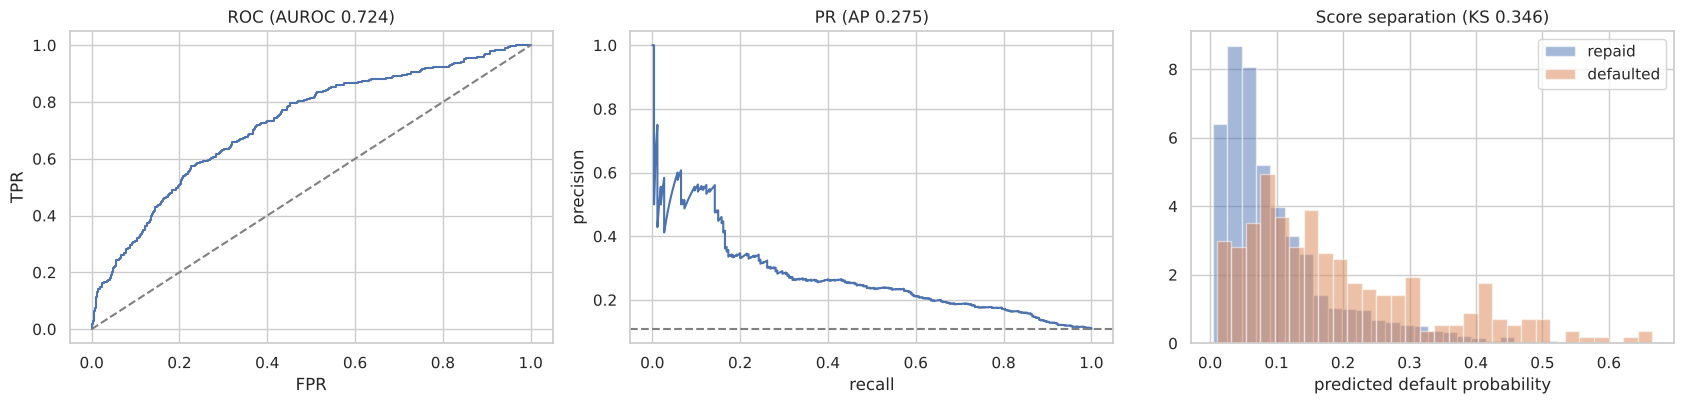

In [13]:
from sklearn.metrics import roc_curve, precision_recall_curve
p = model.predict_proba(holdout[FEATURES])[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
f, t, _ = roc_curve(holdout[TARGET], p); axes[0].plot(f, t); axes[0].plot([0, 1], [0, 1], "--", c="grey"); axes[0].set(title=f"ROC (AUROC {m['auroc']:.3f})", xlabel="FPR", ylabel="TPR")
pr, rc, _ = precision_recall_curve(holdout[TARGET], p); axes[1].plot(rc, pr); axes[1].axhline(holdout[TARGET].mean(), ls="--", c="grey"); axes[1].set(title=f"PR (AP {m['pr_auc']:.3f})", xlabel="recall", ylabel="precision")
for y, lab in [(0, "repaid"), (1, "defaulted")]:
    axes[2].hist(p[holdout[TARGET] == y], bins=30, density=True, alpha=0.5, label=lab)
axes[2].set(title=f"Score separation (KS {m['ks']:.3f})", xlabel="predicted default probability"); axes[2].legend()
plt.tight_layout()

## 7–9. Replaying 60 days of the pipeline
The same functions Airflow calls, run day by day.

In [14]:
from pipeline.orchestrate import simulate
runs = simulate(60)
log = pd.DataFrame([{"day": r["day"], "date": r["date"], "outcome": r["outcome"], "alerts": "; ".join(r.get("alerts", [])),
                     "production": r["production_version"]} for r in runs])
log[log.outcome != "no retraining needed"]

,day,date,outcome,alerts,production
6,6,2026-01-11,model v1 promoted (first model),,1.000
9,9,2026-01-14,model v2 promoted,performance drop: live AUROC 0.655 vs 0.703,2.000
17,17,2026-01-22,batch quarantined,,2.000
23,23,2026-01-28,model v3 promoted,,3.000
26,26,2026-01-31,model v4 rejected (not better than production),data drift: channel,3.000
29,29,2026-02-03,model v5 promoted,data drift: channel,5.000
33,33,2026-02-07,batch quarantined,,5.000
36,36,2026-02-10,model v6 rejected (not better than production),data drift: channel,5.000
40,40,2026-02-14,model v7 rejected (not better than production),performance drop: live AUROC 0.707 vs 0.751,5.000
43,43,2026-02-17,model v8 promoted,performance drop: live AUROC 0.615 vs 0.751,8.000


In [15]:
from pipeline import registry
reg = registry.load_registry()
pd.DataFrame([{"version": v["version"], "stage": v["stage"], "trained_on": v["trained_on"], "reason": v["reason"][:45],
               "auroc": v["metrics"]["auroc"], "ks": v["metrics"]["ks"], "rows": v["train_rows"], "data_fingerprint": v["data_fingerprint"]}
              for v in reg["versions"]])

,version,stage,trained_on,reason,auroc,ks,rows,data_fingerprint
0,1,Archived,2026-01-11,initial model,0.703,0.287,5600,a62097c5ee6ce8c2
1,2,Archived,2026-01-14,performance drop: live AUROC 0.655 vs 0.703,0.677,0.265,8000,9450b63deb97c64e
2,3,Archived,2026-01-28,scheduled refresh,0.747,0.403,16800,ef41a8dd8f0da2f0
3,4,Rejected,2026-01-31,data drift: channel,0.726,0.328,16800,c3fc120cd023144e
4,5,Archived,2026-02-03,data drift: channel,0.751,0.398,16800,d0aeae328ecc6591
5,6,Rejected,2026-02-10,data drift: channel,0.723,0.324,16800,e2c018f2a184e6f3
6,7,Rejected,2026-02-14,performance drop: live AUROC 0.707 vs 0.751,0.707,0.309,16800,95e80cffafb02858
7,8,Archived,2026-02-17,performance drop: live AUROC 0.615 vs 0.751,0.653,0.239,16800,b5bd85ca5f9f43a4
8,9,Production,2026-02-22,performance below floor: live AUROC 0.646 < 0,0.717,0.321,16800,03e78d79e13ab97f


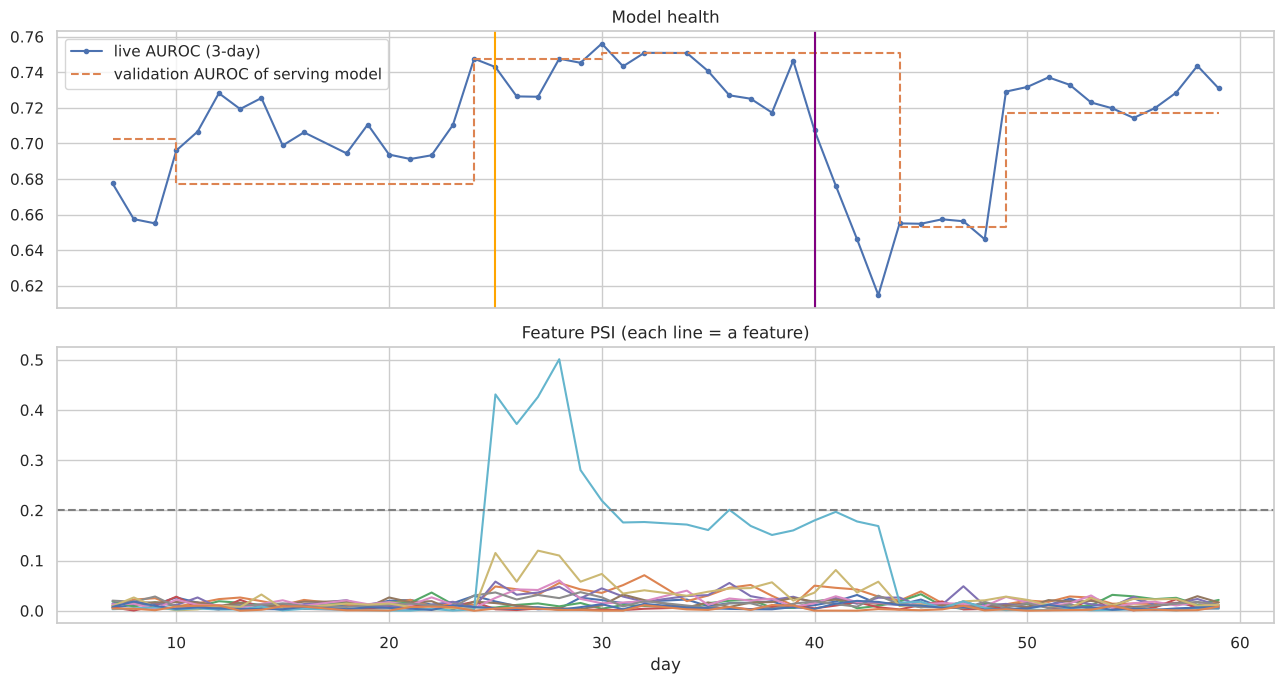

In [16]:
mon = pd.DataFrame([json.loads(l) for l in open("../data/monitoring.jsonl")])
mon["live_auroc"] = mon.live.apply(lambda d: d["auroc"])
mon["day"] = [log.set_index("date").loc[d, "day"] for d in mon.date]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(mon.day, mon.live_auroc, marker="o", ms=3, label="live AUROC (3-day)")
axes[0].step(mon.day, mon.validation_auroc, where="post", ls="--", label="validation AUROC of serving model")
axes[0].axvline(DATA_DRIFT_DAY, c="orange"); axes[0].axvline(CONCEPT_DRIFT_DAY, c="purple"); axes[0].legend(); axes[0].set_title("Model health")
psi_df = pd.DataFrame(list(mon.feature_psi)); psi_df.index = mon.day
psi_df.plot(ax=axes[1], legend=False); axes[1].axhline(0.2, ls="--", c="grey"); axes[1].set_title("Feature PSI (each line = a feature)")
plt.tight_layout()

In [17]:
psi_df.max().sort_values(ascending=False).head(6).to_frame("max PSI over 60 days")

,max PSI over 60 days
channel,0.501
recent_inquiries,0.120
income_k,0.071
debt_to_income,0.060
credit_score,0.058
num_credit_lines,0.037


## 10. Did automation matter?

In [18]:
from pipeline.orchestrate import accepted_batches, load_accepted
last10 = load_accepted([d for d in accepted_batches() if d >= log.date.iloc[-11]])
frozen, _ = registry.load_model(3)
current, cv = registry.load_model()
pd.DataFrame({"frozen v3 (no monitoring)": metrics(last10[TARGET], frozen.predict_proba(last10[FEATURES])[:, 1]),
              f"pipeline v{cv}": metrics(last10[TARGET], current.predict_proba(last10[FEATURES])[:, 1])}).T

,auroc,pr_auc,brier,ks,default_rate,n
frozen v3 (no monitoring),0.631,0.290,0.157,0.202,0.196,"8,800.000"
pipeline v9,0.727,0.397,0.140,0.345,0.196,"8,800.000"


## 11. Ethics and limitations
- Credit decisions are high-stakes. The model supports underwriters and never auto-declines (UK GDPR Art. 22, FCA Consumer Duty).
- Before deployment, check approval rates, AUROC and calibration by age band and other characteristics. See `docs/model_card.md`.
- Every model version records the exact training-data fingerprint, so any decision can be traced back to the model and data that made it.